In [1]:
# ==========================================================
# Section 1: Environment Setup
# Cell 1: Import Required Libraries
# ==========================================================

import os
import random
import warnings
import json
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# Scikit-learn
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# PyTorch
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Progress Bar
from tqdm.auto import tqdm

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# ==========================================================
# Cell 2: Reproducibility & Device Configuration
# ==========================================================

SEED = 42

# Python
random.seed(SEED)

# NumPy
np.random.seed(SEED)

# PyTorch
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 60)
print(f"Using Device : {device}")

if torch.cuda.is_available():
    print(f"GPU Name     : {torch.cuda.get_device_name(0)}")

print("=" * 60)

Using Device : cuda
GPU Name     : Tesla T4


In [3]:
# ==========================================================
# Cell 3: Project Paths
# ==========================================================

PROJECT_ROOT = "/content/drive/MyDrive/model_comparison"

ENGINEERED_DATASET_PATH = (
    f"{PROJECT_ROOT}/dataset/engineered/engineered_dataset.pkl"
)

MODEL_DIR = f"{PROJECT_ROOT}/models"

COMPARISON_DIR = f"{MODEL_DIR}/comparison"

os.makedirs(COMPARISON_DIR, exist_ok=True)

print("=" * 60)
print("Project Root        :", PROJECT_ROOT)
print("Dataset Path        :", ENGINEERED_DATASET_PATH)
print("Model Directory     :", MODEL_DIR)
print("Comparison Directory:", COMPARISON_DIR)
print("=" * 60)

Project Root        : /content/drive/MyDrive/model_comparison
Dataset Path        : /content/drive/MyDrive/model_comparison/dataset/engineered/engineered_dataset.pkl
Model Directory     : /content/drive/MyDrive/model_comparison/models
Comparison Directory: /content/drive/MyDrive/model_comparison/models/comparison


In [4]:
import os

matches = []

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    if "engineered_dataset.pkl" in files:
        matches.append(os.path.join(root, "engineered_dataset.pkl"))

print("Found files:")
for path in matches:
    print(path)

Found files:


In [7]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [8]:
# ==========================================================
# Section 2: Load Engineered Dataset
# Cell 1: Load Dataset
# ==========================================================

print("Loading engineered dataset...\n")

df = pd.read_pickle(
    ENGINEERED_DATASET_PATH
)

print("Dataset loaded successfully.")
print(f"Dataset Shape : {df.shape}")

Loading engineered dataset...

Dataset loaded successfully.
Dataset Shape : (3384445, 49)


In [9]:
# ==========================================================
# Cell 2: Dataset Verification
# ==========================================================

print("=" * 60)
print("Dataset Information")
print("=" * 60)

print(f"Shape             : {df.shape}")
print(
    f"Memory Usage (MB) : "
    f"{df.memory_usage(deep=True).sum() / (1024**2):.2f}"
)

print(f"Missing Values    : {df.isnull().sum().sum()}")
print(f"Duplicate Rows    : {df.duplicated().sum()}")

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

Dataset Information
Shape             : (3384445, 49)
Memory Usage (MB) : 1419.07
Missing Values    : 0
Duplicate Rows    : 0

Columns:
['Flow Duration_Mean', 'Flow Duration_Std', 'Flow Duration_Variance', 'Flow Duration_Min', 'Flow Duration_Max', 'Flow Duration_Renyi', 'Flow Bytes/s_Mean', 'Flow Bytes/s_Std', 'Flow Bytes/s_Variance', 'Flow Bytes/s_Min', 'Flow Bytes/s_Max', 'Flow Bytes/s_Renyi', 'Flow Packets/s_Mean', 'Flow Packets/s_Std', 'Flow Packets/s_Variance', 'Flow Packets/s_Min', 'Flow Packets/s_Max', 'Flow Packets/s_Renyi', 'Packet Length Mean_Mean', 'Packet Length Mean_Std', 'Packet Length Mean_Variance', 'Packet Length Mean_Min', 'Packet Length Mean_Max', 'Packet Length Mean_Renyi', 'Packet Length Std_Mean', 'Packet Length Std_Std', 'Packet Length Std_Variance', 'Packet Length Std_Min', 'Packet Length Std_Max', 'Packet Length Std_Renyi', 'Total Fwd Packets_Mean', 'Total Fwd Packets_Std', 'Total Fwd Packets_Variance', 'Total Fwd Packets_Min', 'Total Fwd Packets_Max', 'Total F

,Flow Duration_Mean,Flow Duration_Std,Flow Duration_Variance,Flow Duration_Min,Flow Duration_Max,Flow Duration_Renyi,Flow Bytes/s_Mean,Flow Bytes/s_Std,Flow Bytes/s_Variance,Flow Bytes/s_Min,...,Total Backward Packets_Min,Total Backward Packets_Max,Total Backward Packets_Renyi,Average Packet Size_Mean,Average Packet Size_Std,Average Packet Size_Variance,Average Packet Size_Min,Average Packet Size_Max,Average Packet Size_Renyi,Label
0,10839530.69,2.843003e+07,8.082669e+14,1,119842965,0.595533,333457.721947,3.083312e+06,9.506815e+12,0.0,...,0,96,0.787368,119.622965,223.877889,50121.309327,0.0,1533.777778,1.270904,BENIGN
1,10505891.36,2.883378e+07,8.313870e+14,96,118514337,0.525330,42053.922346,2.446347e+05,5.984614e+10,0.0,...,0,201,0.696190,184.627261,317.521456,100819.875155,0.0,1784.444444,1.225666,BENIGN
2,12329517.29,3.187952e+07,1.016304e+15,97,118759341,0.586406,65741.641517,2.704786e+05,7.315865e+10,0.0,...,0,260,0.903468,252.496307,416.828398,173745.913406,0.0,1784.444444,1.502260,BENIGN
3,15855919.38,3.638650e+07,1.323977e+15,1,118759341,0.681770,376029.512487,3.089682e+06,9.546132e+12,0.0,...,0,260,1.081308,251.265778,418.410308,175067.185685,0.0,1784.444444,1.682233,BENIGN
4,15815469.62,3.650741e+07,1.332791e+15,1,118759341,0.647016,376991.772878,3.089569e+06,9.545437e+12,0.0,...,0,260,1.043943,254.374859,416.931181,173831.609710,0.0,1784.444444,1.531156,BENIGN


In [10]:
# ==========================================================
# Section 3: Data Preparation
# Cell 1: Label Preparation
# ==========================================================

from sklearn.preprocessing import LabelEncoder

# Standardize inconsistent class name
df["Label"] = df["Label"].replace({
    "UDPLag": "UDP-lag"
})

# Load the EXISTING label encoder
LABEL_ENCODER_PATH = f"{MODEL_DIR}/label_encoder.pkl"

label_encoder = joblib.load(
    LABEL_ENCODER_PATH
)

# Transform labels using the same encoder
df["Label"] = label_encoder.transform(
    df["Label"]
)

class_names = label_encoder.classes_

print("=" * 60)
print("Label Preparation Completed")
print("=" * 60)

print(f"Number of Classes : {len(class_names)}")

print("\nClass Mapping:")

for index, label in enumerate(class_names):
    print(f"{index:2d} --> {label}")

Label Preparation Completed
Number of Classes : 17

Class Mapping:
 0 --> BENIGN
 1 --> DrDoS_DNS
 2 --> DrDoS_LDAP
 3 --> DrDoS_MSSQL
 4 --> DrDoS_NTP
 5 --> DrDoS_NetBIOS
 6 --> DrDoS_SNMP
 7 --> DrDoS_SSDP
 8 --> DrDoS_UDP
 9 --> LDAP
10 --> MSSQL
11 --> NetBIOS
12 --> Portmap
13 --> Syn
14 --> TFTP
15 --> UDP
16 --> UDP-lag


In [11]:
# ==========================================================
# Cell 2: Separate Features and Target
# ==========================================================

X = df.drop(
    columns=["Label"]
)

y = df["Label"]

print("=" * 60)
print("Feature / Target Separation")
print("=" * 60)

print(f"Feature Matrix Shape : {X.shape}")
print(f"Target Vector Shape  : {y.shape}")

print(f"\nNumber of Features   : {X.shape[1]}")
print(f"Number of Classes    : {len(class_names)}")

Feature / Target Separation
Feature Matrix Shape : (3384445, 48)
Target Vector Shape  : (3384445,)

Number of Features   : 48
Number of Classes    : 17


In [12]:
# ==========================================================
# Cell 3: Train / Validation / Test Split
# ==========================================================

from sklearn.model_selection import train_test_split

# First Split:
# 80% Train | 20% Temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

# Second Split:
# 10% Validation | 10% Test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=SEED
)

print("=" * 60)
print("Dataset Split Completed")
print("=" * 60)

print(f"Training Set   : {X_train.shape}")
print(f"Validation Set : {X_val.shape}")
print(f"Test Set       : {X_test.shape}")

Dataset Split Completed
Training Set   : (2707556, 48)
Validation Set : (338444, 48)
Test Set       : (338445, 48)


In [13]:
# ==========================================================
# Cell 4: Load Existing StandardScaler
# ==========================================================

SCALER_PATH = f"{MODEL_DIR}/scaler.pkl"

scaler = joblib.load(
    SCALER_PATH
)

print("=" * 60)
print("Existing StandardScaler Loaded")
print("=" * 60)

# Apply exactly the same scaler
X_train = scaler.transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print(f"Training Set   : {X_train.shape}")
print(f"Validation Set : {X_val.shape}")
print(f"Test Set       : {X_test.shape}")

Existing StandardScaler Loaded
Training Set   : (2707556, 48)
Validation Set : (338444, 48)
Test Set       : (338445, 48)


In [14]:
# ==========================================================
# Section 4: PyTorch Dataset
# Cell 1: Dataset Class
# ==========================================================

class DDoSDataset(Dataset):

    def __init__(self, features, labels):
        self.features = features
        self.labels = labels

    def __len__(self):
        return len(self.features)

    def __getitem__(self, idx):

        # Convert feature vector to tensor
        x = torch.tensor(
            self.features[idx],
            dtype=torch.float32
        )

        # (48,) -> (1, 48)
        x = x.unsqueeze(0)

        # Label
        y = torch.tensor(
            self.labels[idx],
            dtype=torch.long
        )

        return x, y

In [15]:
# ==========================================================
# Cell 2: Create Dataset Objects
# ==========================================================

train_dataset = DDoSDataset(
    X_train,
    y_train.values
)

val_dataset = DDoSDataset(
    X_val,
    y_val.values
)

test_dataset = DDoSDataset(
    X_test,
    y_test.values
)

print("=" * 60)
print("Datasets Created")
print("=" * 60)

print(f"Training Samples   : {len(train_dataset):,}")
print(f"Validation Samples : {len(val_dataset):,}")
print(f"Test Samples       : {len(test_dataset):,}")

Datasets Created
Training Samples   : 2,707,556
Validation Samples : 338,444
Test Samples       : 338,445


In [16]:
# ==========================================================
# Cell 3: Create DataLoaders
# ==========================================================

BATCH_SIZE = 512

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

print("=" * 60)
print("DataLoaders Created")
print("=" * 60)

print(f"Batch Size : {BATCH_SIZE}")

DataLoaders Created
Batch Size : 512


In [17]:
# ==========================================================
# Cell 4: Verify DataLoader
# ==========================================================

X_batch, y_batch = next(
    iter(train_loader)
)

print("=" * 60)
print("Batch Verification")
print("=" * 60)

print(f"Feature Batch Shape : {X_batch.shape}")
print(f"Label Batch Shape   : {y_batch.shape}")

print(f"\nFeature Data Type   : {X_batch.dtype}")
print(f"Label Data Type     : {y_batch.dtype}")

Batch Verification
Feature Batch Shape : torch.Size([512, 1, 48])
Label Batch Shape   : torch.Size([512])

Feature Data Type   : torch.float32
Label Data Type     : torch.int64


In [18]:
class CNNModel(nn.Module):
    def __init__(self, num_classes=17):
        super().__init__()

        self.cnn = nn.Sequential(
            nn.Conv1d(1, 64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),

            nn.Conv1d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2)
        )

        self.pool = nn.AdaptiveAvgPool1d(1)

        self.classifier = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        x = self.cnn(x)
        x = self.pool(x)
        x = x.squeeze(-1)
        x = self.classifier(x)

        return x

In [19]:
class BiLSTMModel(nn.Module):
    def __init__(self, num_classes=17):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=128,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )

        self.classifier = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        # (batch, 1, 48) -> (batch, 48, 1)
        x = x.squeeze(1).unsqueeze(-1)

        x, _ = self.lstm(x)

        # Mean representation across sequence
        x = x.mean(dim=1)

        x = self.classifier(x)

        return x

In [20]:
class CNNBiLSTMModel(nn.Module):
    def __init__(self, num_classes=17):
        super().__init__()

        self.cnn = nn.Sequential(
            nn.Conv1d(1, 64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),

            nn.Conv1d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2)
        )

        self.lstm = nn.LSTM(
            input_size=128,
            hidden_size=128,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )

        self.classifier = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):

        # CNN
        x = self.cnn(x)

        # (batch, channels, sequence)
        # -> (batch, sequence, channels)
        x = x.permute(0, 2, 1)

        # BiLSTM
        x, _ = self.lstm(x)

        # Aggregate sequence representation
        x = x.mean(dim=1)

        # Classifier
        x = self.classifier(x)

        return x

In [21]:
# ============================================================
# CELL 17 — INITIALIZE MODELS
# Purpose:
# Create the three models that will be trained and compared.
# ============================================================

# Number of output classes
num_classes = len(class_names)

print("Number of classes:", num_classes)

# Create CNN model
cnn_model = CNNModel(
    num_classes=num_classes
).to(device)

# Create standalone BiLSTM model
bilstm_model = BiLSTMModel(
    num_classes=num_classes
).to(device)

# Create CNN + BiLSTM model
cnn_bilstm_model = CNNBiLSTMModel(
    num_classes=num_classes
).to(device)

print("\nModels initialized successfully.")
print("Device:", device)

Number of classes: 17

Models initialized successfully.
Device: cuda


In [22]:
# ============================================================
# LOAD PREVIOUSLY TRAINED CNN AND BiLSTM MODELS
# Purpose:
# Restore the trained weights saved during the previous
# Colab session so that CNN and BiLSTM do not need to be
# trained again.
# ============================================================

cnn_model.load_state_dict(
    torch.load(
        f"{COMPARISON_DIR}/cnn_model.pth",
        map_location=device
    )
)

bilstm_model.load_state_dict(
    torch.load(
        f"{COMPARISON_DIR}/bilstm_model.pth",
        map_location=device
    )
)

cnn_model = cnn_model.to(device)
bilstm_model = bilstm_model.to(device)

print("CNN trained weights loaded successfully.")
print("BiLSTM trained weights loaded successfully.")

CNN trained weights loaded successfully.
BiLSTM trained weights loaded successfully.


In [23]:
# ============================================================
# VERIFY LOADED MODELS
# Purpose:
# Confirm that the previously trained CNN and BiLSTM weights
# are available before continuing the experiment.
# ============================================================

print(
    "CNN model parameters:",
    sum(p.numel() for p in cnn_model.parameters())
)

print(
    "BiLSTM model parameters:",
    sum(p.numel() for p in bilstm_model.parameters())
)

CNN model parameters: 34705
BiLSTM model parameters: 151697


In [24]:
# ============================================================
# CELL 18 — VERIFY MODEL OUTPUTS
# Purpose:
# Confirm that all three models accept the dataset format
# and produce 17-class predictions.
# ============================================================

# Get one batch from the test dataset
X_batch, y_batch = next(iter(test_loader))

# Move input to GPU/CPU
X_batch = X_batch.to(device)

# Disable gradient calculation because this is only a test
with torch.no_grad():

    cnn_output = cnn_model(X_batch)

    bilstm_output = bilstm_model(X_batch)

    cnn_bilstm_output = cnn_bilstm_model(X_batch)

# Print input and output shapes
print("Input shape:")
print(X_batch.shape)

print("\nCNN output:")
print(cnn_output.shape)

print("\nBiLSTM output:")
print(bilstm_output.shape)

print("\nCNN + BiLSTM output:")
print(cnn_bilstm_output.shape)

print("\nExpected output:")
print((X_batch.shape[0], num_classes))

Input shape:
torch.Size([512, 1, 48])

CNN output:
torch.Size([512, 17])

BiLSTM output:
torch.Size([512, 17])

CNN + BiLSTM output:
torch.Size([512, 17])

Expected output:
(512, 17)


In [25]:
# ============================================================
# CELL 19 — COMMON TRAINING FUNCTION
# Purpose:
# Train any of the comparison models using the same:
# - optimizer
# - learning rate
# - batch size
# - loss function
# - learning-rate scheduler
# - gradient clipping
# - early stopping
#
# This makes the model comparison more controlled.
# ============================================================

def train_model(
    model,
    model_name,
    train_loader,
    val_loader,
    num_epochs=30,
    learning_rate=0.001,
    weight_decay=0.0001,
    patience=5
):

    # Move model to the selected device
    model = model.to(device)

    # Classification loss
    criterion = nn.CrossEntropyLoss()

    # AdamW optimizer
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    # Reduce learning rate when validation loss stops improving
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=2
    )

    # Track the best validation loss
    best_val_loss = float("inf")

    # Store the best model weights
    best_state = None

    # Count epochs without improvement
    epochs_without_improvement = 0

    # Store training history
    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    # Where the best model will be saved
    save_path = os.path.join(
        COMPARISON_DIR,
        f"{model_name}_model.pth"
    )

    # --------------------------------------------------------
    # Training loop
    # --------------------------------------------------------

    for epoch in range(num_epochs):

        # ============================
        # TRAINING
        # ============================

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        progress_bar = tqdm(
            train_loader,
            desc=f"{model_name} | Epoch {epoch + 1}/{num_epochs}"
        )

        for X_batch, y_batch in progress_bar:

            # Move data to GPU/CPU
            X_batch = X_batch.to(
                device,
                non_blocking=True
            )

            y_batch = y_batch.to(
                device,
                non_blocking=True
            )

            # Clear previous gradients
            optimizer.zero_grad()

            # Forward pass
            outputs = model(X_batch)

            # Calculate loss
            loss = criterion(
                outputs,
                y_batch
            )

            # Backpropagation
            loss.backward()

            # Prevent exploding gradients
            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            # Update model parameters
            optimizer.step()

            # Accumulate loss
            running_loss += (
                loss.item() * X_batch.size(0)
            )

            # Calculate predictions
            predictions = outputs.argmax(dim=1)

            # Count correct predictions
            correct += (
                predictions == y_batch
            ).sum().item()

            total += y_batch.size(0)

        # Average training loss
        train_loss = running_loss / total

        # Training accuracy
        train_accuracy = correct / total

        # ============================
        # VALIDATION
        # ============================

        model.eval()

        val_running_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for X_batch, y_batch in val_loader:

                X_batch = X_batch.to(
                    device,
                    non_blocking=True
                )

                y_batch = y_batch.to(
                    device,
                    non_blocking=True
                )

                # Forward pass
                outputs = model(X_batch)

                # Validation loss
                loss = criterion(
                    outputs,
                    y_batch
                )

                val_running_loss += (
                    loss.item() * X_batch.size(0)
                )

                # Predictions
                predictions = outputs.argmax(dim=1)

                val_correct += (
                    predictions == y_batch
                ).sum().item()

                val_total += y_batch.size(0)

        # Average validation loss
        val_loss = val_running_loss / val_total

        # Validation accuracy
        val_accuracy = val_correct / val_total

        # Update learning-rate scheduler
        scheduler.step(val_loss)

        # Save metrics
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_accuracy)
        history["val_acc"].append(val_accuracy)

        # Display epoch results
        print(
            f"Epoch {epoch + 1:02d} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_accuracy:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_accuracy:.4f}"
        )

        # ============================
        # SAVE BEST MODEL
        # ============================

        if val_loss < best_val_loss:

            best_val_loss = val_loss

            # Copy the best weights to CPU memory
            best_state = {
                key: value.cpu().clone()
                for key, value in model.state_dict().items()
            }

            epochs_without_improvement = 0

            # Save best model weights
            torch.save(
                best_state,
                save_path
            )

            print("  ✓ Best model saved")

        else:

            epochs_without_improvement += 1

            # Early stopping
            if epochs_without_improvement >= patience:

                print("  Early stopping triggered.")
                break

    # Restore best model
    if best_state is not None:
        model.load_state_dict(best_state)

    print("\nTraining completed.")
    print("Best model saved at:")
    print(save_path)

    return model, history

In [ ]:
# ============================================================
# CELL 20 — TRAIN CNN
# Purpose:
# Train the standalone CNN model using the common training
# configuration.
# ============================================================

cnn_model, cnn_history = train_model(
    model=cnn_model,
    model_name="cnn",
    train_loader=train_loader,
    val_loader=val_loader
)

cnn | Epoch 1/30:   0%|          | 0/5289 [00:00<?, ?it/s]

Epoch 01 | Train Loss: 0.4006 | Train Acc: 0.8364 | Val Loss: 0.3348 | Val Acc: 0.8529
  ✓ Best model saved


cnn | Epoch 2/30:   0%|          | 0/5289 [00:00<?, ?it/s]

Epoch 02 | Train Loss: 0.3343 | Train Acc: 0.8590 | Val Loss: 0.3213 | Val Acc: 0.8569
  ✓ Best model saved


cnn | Epoch 3/30:   0%|          | 0/5289 [00:00<?, ?it/s]

...

Epoch 28 | Train Loss: 0.2885 | Train Acc: 0.8786 | Val Loss: 0.2731 | Val Acc: 0.8840


cnn | Epoch 29/30:   0%|          | 0/5289 [00:00<?, ?it/s]

Epoch 29 | Train Loss: 0.2879 | Train Acc: 0.8790 | Val Loss: 0.2724 | Val Acc: 0.8848
  ✓ Best model saved


cnn | Epoch 30/30:   0%|          | 0/5289 [00:00<?, ?it/s]

Epoch 30 | Train Loss: 0.2881 | Train Acc: 0.8787 | Val Loss: 0.2777 | Val Acc: 0.8808

Training completed.
Best model saved at:
/content/drive/MyDrive/model_comparison/models/comparison/cnn_model.pth


In [ ]:
# ============================================================
# CELL 21 — TRAIN BiLSTM
# Purpose:
# Train the standalone BiLSTM model.
# ============================================================

bilstm_model, bilstm_history = train_model(
    model=bilstm_model,
    model_name="bilstm",
    train_loader=train_loader,
    val_loader=val_loader
)

bilstm | Epoch 1/30:   0%|          | 0/5289 [00:00<?, ?it/s]

Epoch 01 | Train Loss: 0.4628 | Train Acc: 0.8084 | Val Loss: 0.3221 | Val Acc: 0.8607
  ✓ Best model saved


bilstm | Epoch 2/30:   0%|          | 0/5289 [00:00<?, ?it/s]

Epoch 02 | Train Loss: 0.3220 | Train Acc: 0.8640 | Val Loss: 0.3091 | Val Acc: 0.8694
  ✓ Best model saved


bilstm | Epoch 3/30:   0%|          | 0/5289 [00:00<?, ?it/s]

...

Epoch 28 | Train Loss: 0.2516 | Train Acc: 0.8941 | Val Loss: 0.2493 | Val Acc: 0.8947
  ✓ Best model saved


bilstm | Epoch 29/30:   0%|          | 0/5289 [00:00<?, ?it/s]

Epoch 29 | Train Loss: 0.2513 | Train Acc: 0.8944 | Val Loss: 0.2493 | Val Acc: 0.8946


bilstm | Epoch 30/30:   0%|          | 0/5289 [00:00<?, ?it/s]

Epoch 30 | Train Loss: 0.2510 | Train Acc: 0.8944 | Val Loss: 0.2491 | Val Acc: 0.8947
  ✓ Best model saved

Training completed.
Best model saved at:
/content/drive/MyDrive/model_comparison/models/comparison/bilstm_model.pth


In [26]:
# ============================================================
# CELL 22 — TRAIN CNN + BiLSTM
# Purpose:
# Train the CNN + BiLSTM model without Attention.
# ============================================================

cnn_bilstm_model, cnn_bilstm_history = train_model(
    model=cnn_bilstm_model,
    model_name="cnn_bilstm",
    train_loader=train_loader,
    val_loader=val_loader
)

cnn_bilstm | Epoch 1/30:   0%|          | 0/5289 [00:00<?, ?it/s]

Epoch 01 | Train Loss: 0.3298 | Train Acc: 0.8637 | Val Loss: 0.2886 | Val Acc: 0.8784
  ✓ Best model saved


cnn_bilstm | Epoch 2/30:   0%|          | 0/5289 [00:00<?, ?it/s]

Epoch 02 | Train Loss: 0.2916 | Train Acc: 0.8779 | Val Loss: 0.2775 | Val Acc: 0.8827
  ✓ Best model saved


cnn_bilstm | Epoch 3/30:   0%|          | 0/5289 [00:00<?, ?it/s]

...

Epoch 28 | Train Loss: 0.2492 | Train Acc: 0.8953 | Val Loss: 0.2548 | Val Acc: 0.8928


cnn_bilstm | Epoch 29/30:   0%|          | 0/5289 [00:00<?, ?it/s]

Epoch 29 | Train Loss: 0.2485 | Train Acc: 0.8955 | Val Loss: 0.2460 | Val Acc: 0.8960
  ✓ Best model saved


cnn_bilstm | Epoch 30/30:   0%|          | 0/5289 [00:00<?, ?it/s]

Epoch 30 | Train Loss: 0.2481 | Train Acc: 0.8956 | Val Loss: 0.2460 | Val Acc: 0.8960
  ✓ Best model saved

Training completed.
Best model saved at:
/content/drive/MyDrive/model_comparison/models/comparison/cnn_bilstm_model.pth


In [39]:
# ============================================================
# NEW CELL — CNN + BiLSTM + Attention MODEL
# Purpose:
# Recreate the hybrid architecture used in the original
# StealthGuard model so it can be retrained under the same
# experimental conditions as the other comparison models.
# ============================================================

class HybridDDoSModel(nn.Module):

    def __init__(self, num_classes=17):
        super().__init__()

        # ----------------------------------------------------
        # CNN
        # Extract local patterns from the 48 engineered features
        # ----------------------------------------------------
        self.cnn = nn.Sequential(

            nn.Conv1d(
                in_channels=1,
                out_channels=64,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm1d(64),
            nn.ReLU(),

            nn.MaxPool1d(kernel_size=2),

            nn.Conv1d(
                in_channels=64,
                out_channels=128,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm1d(128),
            nn.ReLU(),

            nn.MaxPool1d(kernel_size=2)
        )

        # ----------------------------------------------------
        # BiLSTM
        # Captures sequential dependencies in CNN features
        # ----------------------------------------------------
        self.lstm = nn.LSTM(
            input_size=128,
            hidden_size=128,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )

        # BiLSTM output:
        # 128 forward + 128 backward = 256
        self.attention = nn.Linear(256, 1)

        # ----------------------------------------------------
        # Fully connected classifier
        # ----------------------------------------------------
        self.classifier = nn.Sequential(

            nn.Dropout(0.3),

            nn.Linear(256, 64),

            nn.ReLU(),

            nn.Dropout(0.2),

            nn.Linear(64, num_classes)
        )

    def forward(self, x):

        # x shape:
        # [batch, 1, 48]

        # CNN
        x = self.cnn(x)

        # After CNN:
        # [batch, 128, sequence_length]

        # Convert to:
        # [batch, sequence_length, 128]
        x = x.permute(0, 2, 1)

        # BiLSTM
        x, _ = self.lstm(x)

        # x:
        # [batch, sequence_length, 256]

        # Attention scores
        attention_scores = self.attention(x)

        # Convert scores to attention weights
        attention_weights = torch.softmax(
            attention_scores,
            dim=1
        )

        # Weighted sum of BiLSTM outputs
        context = torch.sum(
            attention_weights * x,
            dim=1
        )

        # Classifier
        output = self.classifier(context)

        return output

In [40]:
# ============================================================
# NEW CELL — CREATE HYBRID MODEL
# ============================================================

hybrid_model = HybridDDoSModel(
    num_classes=num_classes
).to(device)

print(hybrid_model)

HybridDDoSModel(
  (cnn): Sequential(
    (0): Conv1d(1, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,))
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (lstm): LSTM(128, 128, batch_first=True, bidirectional=True)
  (attention): Linear(in_features=256, out_features=1, bias=True)
  (classifier): Sequential(
    (0): Dropout(p=0.3, inplace=False)
    (1): Linear(in_features=256, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=64, out_features=17, bias=True)
  )
)


In [41]:
# ============================================================
# NEW CELL — VERIFY HYBRID MODEL
# ============================================================

X_batch, y_batch = next(iter(test_loader))

X_batch = X_batch.to(device)

with torch.no_grad():

    hybrid_output = hybrid_model(X_batch)

print("Input shape :", X_batch.shape)
print("Output shape:", hybrid_output.shape)
print("Expected    :", (X_batch.shape[0], num_classes))

Input shape : torch.Size([512, 1, 48])
Output shape: torch.Size([512, 17])
Expected    : (512, 17)


In [42]:
# ============================================================
# NEW CELL — TRAIN CNN + BiLSTM + ATTENTION
# ============================================================

hybrid_model, hybrid_history = train_model(
    model=hybrid_model,
    model_name="hybrid_comparison",
    train_loader=train_loader,
    val_loader=val_loader
)

hybrid_comparison | Epoch 1/30:   0%|          | 0/5289 [00:00<?, ?it/s]

Epoch 01 | Train Loss: 0.3257 | Train Acc: 0.8658 | Val Loss: 0.2934 | Val Acc: 0.8778
  ✓ Best model saved


hybrid_comparison | Epoch 2/30:   0%|          | 0/5289 [00:00<?, ?it/s]

Epoch 02 | Train Loss: 0.2898 | Train Acc: 0.8788 | Val Loss: 0.2806 | Val Acc: 0.8818
  ✓ Best model saved


hybrid_comparison | Epoch 3/30:   0%|          | 0/5289 [00:00<?, ?it/s]

...

Epoch 28 | Train Loss: 0.2469 | Train Acc: 0.8962 | Val Loss: 0.2453 | Val Acc: 0.8965
  ✓ Best model saved


hybrid_comparison | Epoch 29/30:   0%|          | 0/5289 [00:00<?, ?it/s]

Epoch 29 | Train Loss: 0.2465 | Train Acc: 0.8964 | Val Loss: 0.2456 | Val Acc: 0.8961


hybrid_comparison | Epoch 30/30:   0%|          | 0/5289 [00:00<?, ?it/s]

Epoch 30 | Train Loss: 0.2462 | Train Acc: 0.8965 | Val Loss: 0.2481 | Val Acc: 0.8953

Training completed.
Best model saved at:
/content/drive/MyDrive/model_comparison/models/comparison/hybrid_comparison_model.pth


In [43]:
# ============================================================
# CELL 24 — MODEL EVALUATION FUNCTION
# Purpose:
# Evaluate a trained model on the common test set and calculate:
# - Accuracy
# - Macro Precision
# - Macro Recall
# - Macro F1
# - Weighted F1
# - Classification report
# - Confusion matrix
# ============================================================

def evaluate_model(
    model,
    test_loader,
    class_names
):

    # Put model in evaluation mode
    model.eval()

    all_predictions = []
    all_labels = []

    # Disable gradients during evaluation
    with torch.no_grad():

        for X_batch, y_batch in tqdm(
            test_loader,
            desc="Evaluating"
        ):

            # Move input to device
            X_batch = X_batch.to(device)

            # Generate predictions
            outputs = model(X_batch)

            predictions = outputs.argmax(dim=1)

            # Store predictions and true labels
            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                y_batch.numpy()
            )

    # Convert lists to NumPy arrays
    y_true = np.array(all_labels)
    y_pred = np.array(all_predictions)

    # Calculate evaluation metrics
    metrics = {

        "Accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "Macro Precision": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Macro Recall": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Macro F1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "Weighted F1": f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        )
    }

    # Per-class classification report
    report = classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        zero_division=0,
        output_dict=True
    )

    # Confusion matrix
    cm = confusion_matrix(
        y_true,
        y_pred
    )

    return (
        metrics,
        report,
        cm,
        y_true,
        y_pred
    )

In [44]:
# ============================================================
# CELL 25 — EVALUATE CNN
# Purpose:
# Evaluate the trained CNN on the test set.
# ============================================================

cnn_metrics, cnn_report, cnn_cm, cnn_y_true, cnn_y_pred = evaluate_model(
    model=cnn_model,
    test_loader=test_loader,
    class_names=class_names
)

print("CNN Results")
print("=" * 50)

for metric, value in cnn_metrics.items():
    print(f"{metric}: {value:.4f}")

Evaluating:   0%|          | 0/662 [00:00<?, ?it/s]

CNN Results
Accuracy: 0.8842
Macro Precision: 0.8462
Macro Recall: 0.7896
Macro F1: 0.7939
Weighted F1: 0.8803


In [45]:
# ============================================================
# CELL 26 — EVALUATE BiLSTM
# Purpose:
# Evaluate the trained standalone BiLSTM on the same test set.
# ============================================================

bilstm_metrics, bilstm_report, bilstm_cm, bilstm_y_true, bilstm_y_pred = evaluate_model(
    model=bilstm_model,
    test_loader=test_loader,
    class_names=class_names
)

print("BiLSTM Results")
print("=" * 50)

for metric, value in bilstm_metrics.items():
    print(f"{metric}: {value:.4f}")

Evaluating:   0%|          | 0/662 [00:00<?, ?it/s]

BiLSTM Results
Accuracy: 0.8941
Macro Precision: 0.8592
Macro Recall: 0.8068
Macro F1: 0.8160
Weighted F1: 0.8916


In [46]:
# ============================================================
# CELL 27 — EVALUATE CNN + BiLSTM
# Purpose:
# Evaluate the CNN + BiLSTM model on the same test set.
# ============================================================

cnn_bilstm_metrics, cnn_bilstm_report, cnn_bilstm_cm, \
cnn_bilstm_y_true, cnn_bilstm_y_pred = evaluate_model(
    model=cnn_bilstm_model,
    test_loader=test_loader,
    class_names=class_names
)

print("CNN + BiLSTM Results")
print("=" * 50)

for metric, value in cnn_bilstm_metrics.items():
    print(f"{metric}: {value:.4f}")

Evaluating:   0%|          | 0/662 [00:00<?, ?it/s]

CNN + BiLSTM Results
Accuracy: 0.8960
Macro Precision: 0.8558
Macro Recall: 0.8103
Macro F1: 0.8197
Weighted F1: 0.8942


In [47]:
# ============================================================
# EVALUATE CNN + BiLSTM + ATTENTION
# ============================================================

hybrid_metrics, hybrid_report, hybrid_cm, hybrid_y_true, hybrid_y_pred = evaluate_model(
    model=hybrid_model,
    test_loader=test_loader,
    class_names=class_names
)

print("Hybrid Model Metrics:")
for metric, value in hybrid_metrics.items():
    print(f"{metric}: {value:.4f}")

Evaluating:   0%|          | 0/662 [00:00<?, ?it/s]

Hybrid Model Metrics:
Accuracy: 0.8960
Macro Precision: 0.8577
Macro Recall: 0.8103
Macro F1: 0.8193
Weighted F1: 0.8939


In [48]:
# ============================================================
# CELL 28 — STANDARDIZED MODEL COMPARISON TABLE
# ============================================================
# Combines the evaluation results from all four models.
#
# Models:
# 1. CNN
# 2. BiLSTM
# 3. CNN + BiLSTM
# 4. CNN + BiLSTM + Attention
#
# All metrics are taken directly from the current evaluation
# results, including the newly retrained hybrid model.
# ============================================================

comparison_results = pd.DataFrame({

    "Model": [
        "CNN",
        "BiLSTM",
        "CNN + BiLSTM",
        "CNN + BiLSTM + Attention"
    ],

    "Accuracy": [
        cnn_metrics["Accuracy"],
        bilstm_metrics["Accuracy"],
        cnn_bilstm_metrics["Accuracy"],
        hybrid_metrics["Accuracy"]
    ],

    "Macro Precision": [
        cnn_metrics["Macro Precision"],
        bilstm_metrics["Macro Precision"],
        cnn_bilstm_metrics["Macro Precision"],
        hybrid_metrics["Macro Precision"]
    ],

    "Macro Recall": [
        cnn_metrics["Macro Recall"],
        bilstm_metrics["Macro Recall"],
        cnn_bilstm_metrics["Macro Recall"],
        hybrid_metrics["Macro Recall"]
    ],

    "Macro F1": [
        cnn_metrics["Macro F1"],
        bilstm_metrics["Macro F1"],
        cnn_bilstm_metrics["Macro F1"],
        hybrid_metrics["Macro F1"]
    ],

    "Weighted F1": [
        cnn_metrics["Weighted F1"],
        bilstm_metrics["Weighted F1"],
        cnn_bilstm_metrics["Weighted F1"],
        hybrid_metrics["Weighted F1"]
    ]
})

# Display the comparison table
comparison_results

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,CNN,0.884185,0.846200,0.789570,0.793866,0.880276
1,BiLSTM,0.894136,0.859191,0.806808,0.816006,0.891600
2,CNN + BiLSTM,0.895965,0.855790,0.810269,0.819668,0.894209
3,CNN + BiLSTM + Attention,0.896024,0.857708,0.810254,0.819282,0.893890


In [49]:
# Cell 29: Convert metric values to percentages for easier interpretation

comparison_display = comparison_results.copy()

metric_columns = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Weighted F1"
]

comparison_display[metric_columns] = (
    comparison_display[metric_columns] * 100
).round(2)

display(comparison_display)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,CNN,88.42,84.62,78.96,79.39,88.03
1,BiLSTM,89.41,85.92,80.68,81.60,89.16
2,CNN + BiLSTM,89.60,85.58,81.03,81.97,89.42
3,CNN + BiLSTM + Attention,89.60,85.77,81.03,81.93,89.39


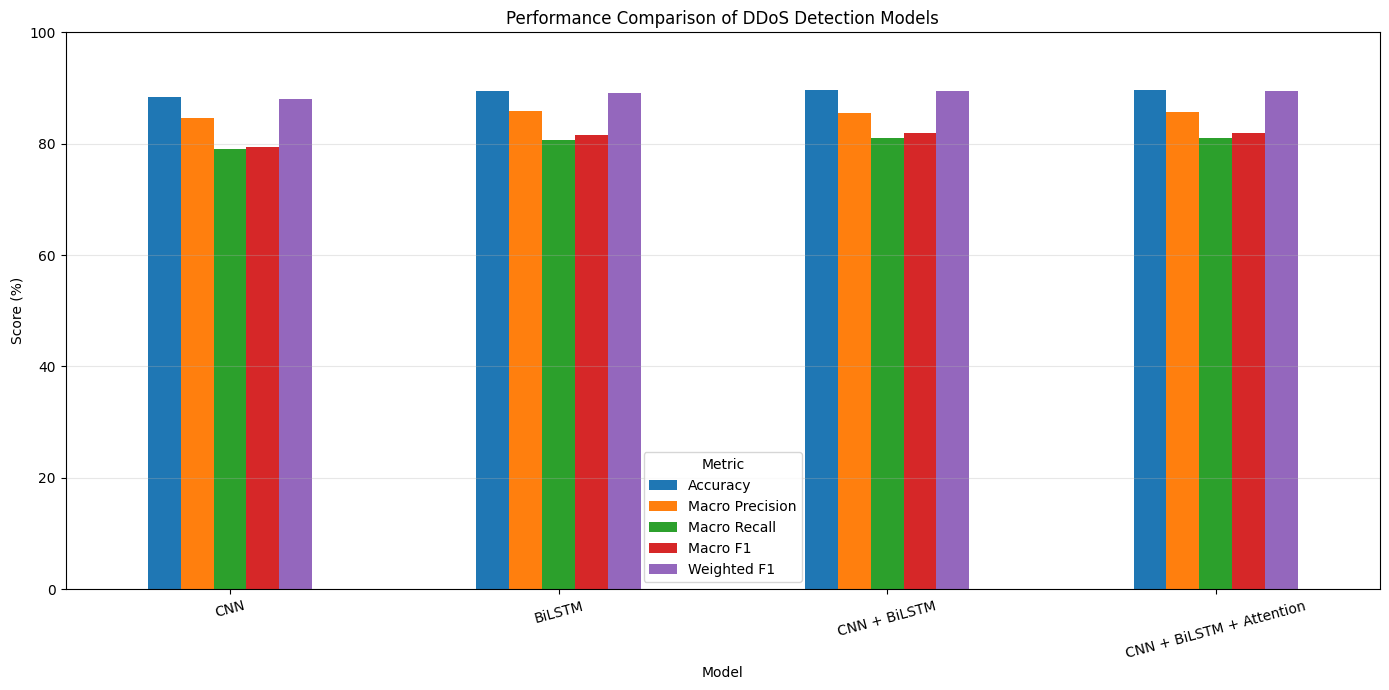

In [50]:
# Cell 30: Plot all evaluation metrics for all four models

plot_data = comparison_display.set_index("Model")

plot_data[[
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Weighted F1"
]].plot(
    kind="bar",
    figsize=(14, 7)
)

plt.title("Performance Comparison of DDoS Detection Models")
plt.ylabel("Score (%)")
plt.xlabel("Model")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.legend(title="Metric")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

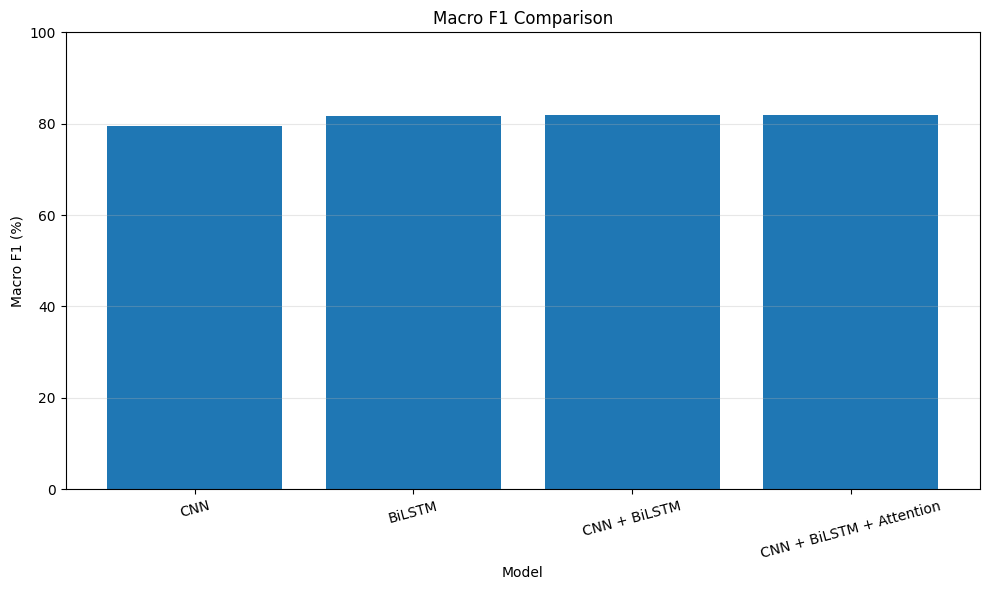

In [52]:
# Cell 32: Compare Macro F1 across all models

plt.figure(figsize=(10, 6))

plt.bar(
    comparison_display["Model"],
    comparison_display["Macro F1"]
)

plt.title("Macro F1 Comparison")
plt.ylabel("Macro F1 (%)")
plt.xlabel("Model")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

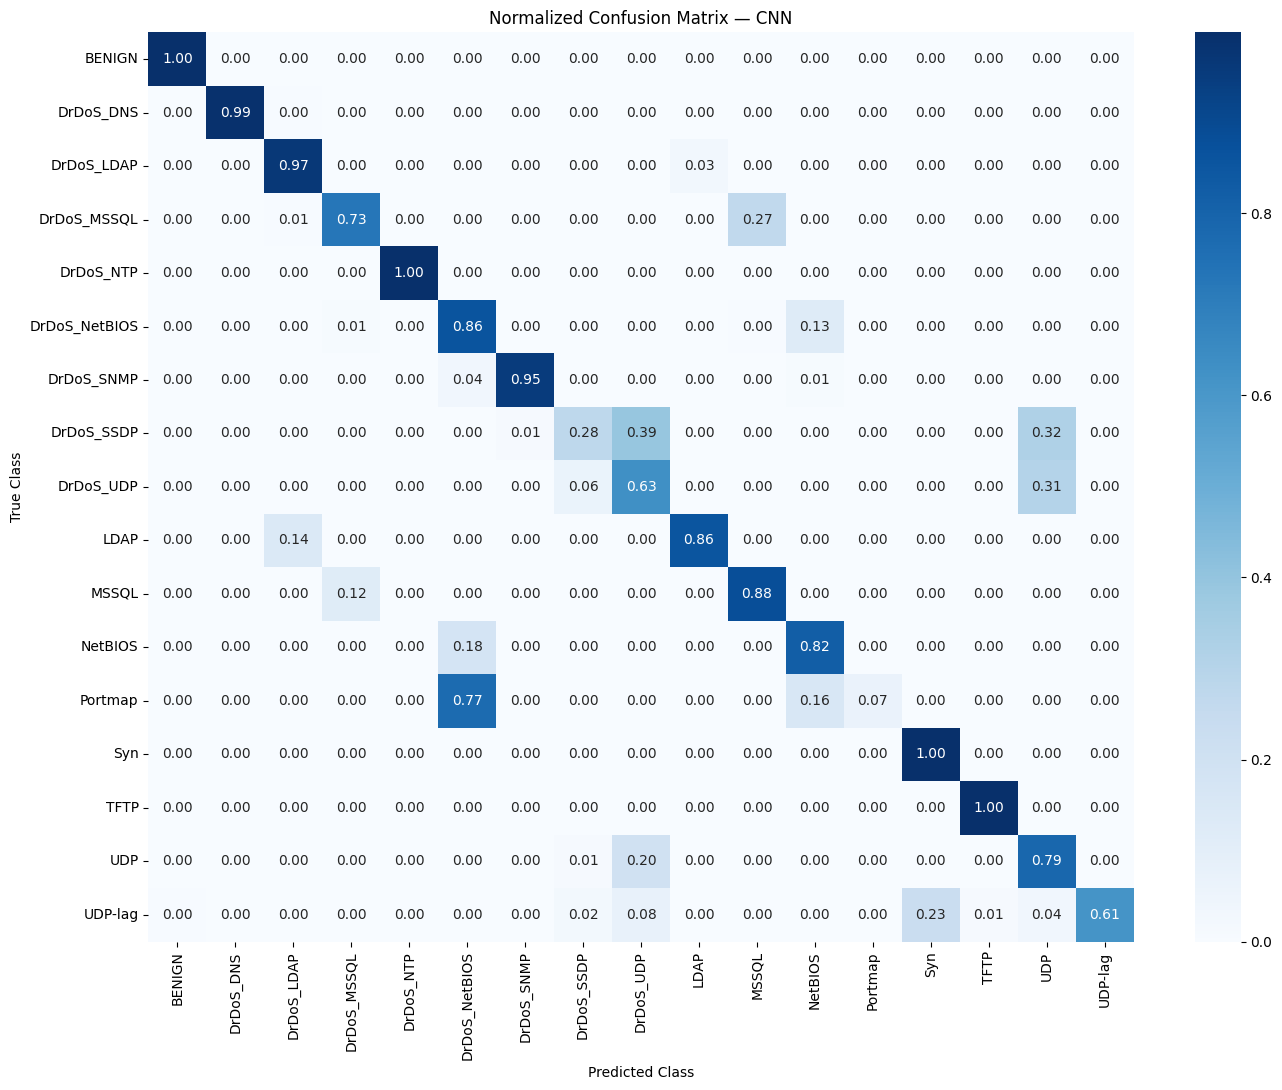

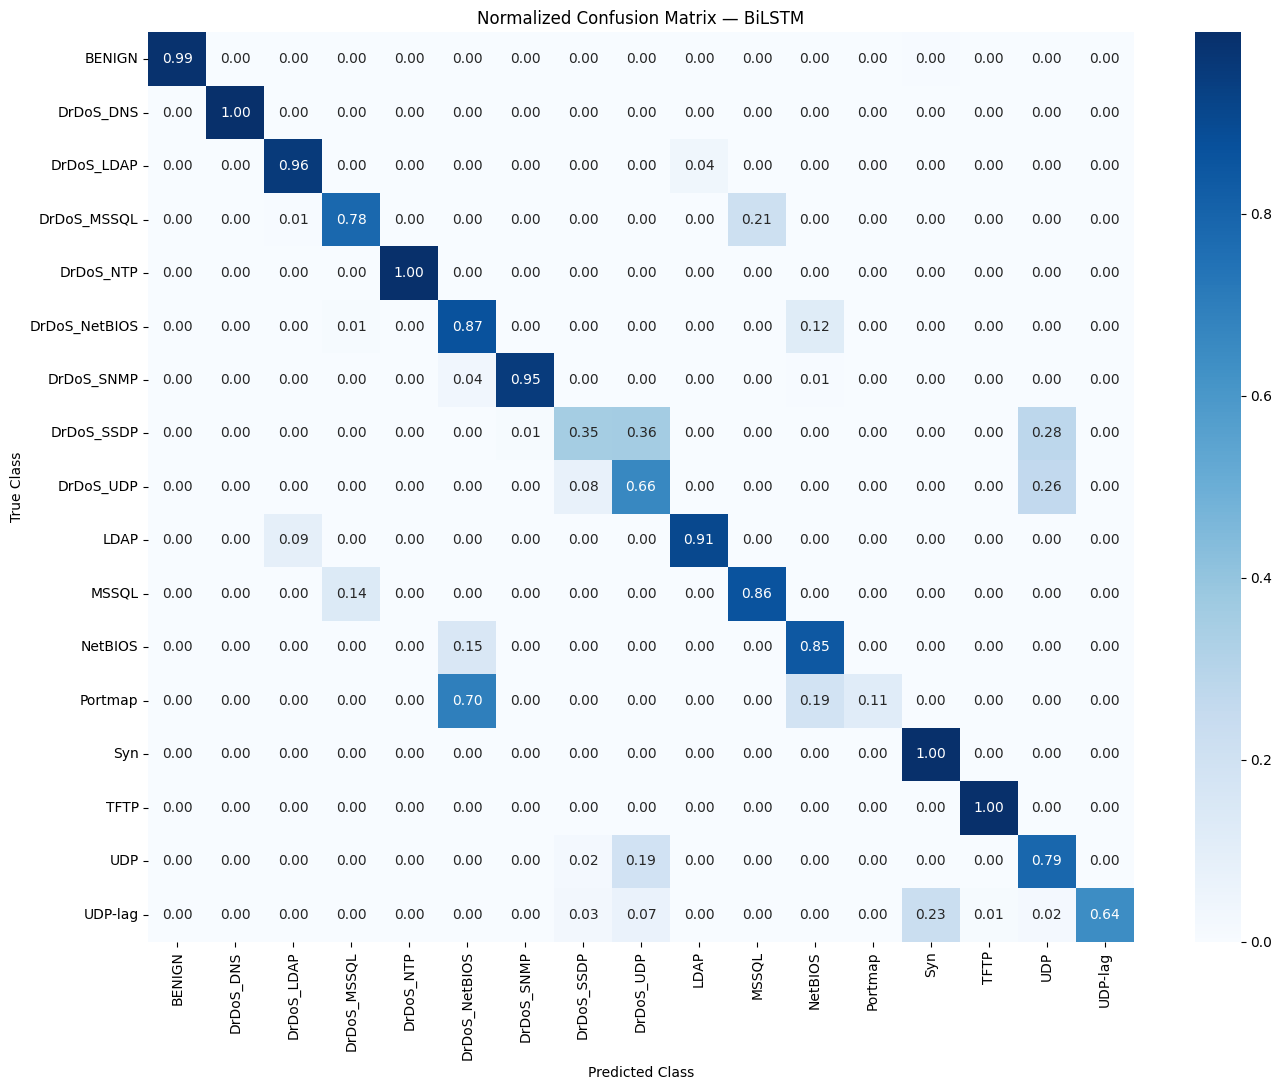

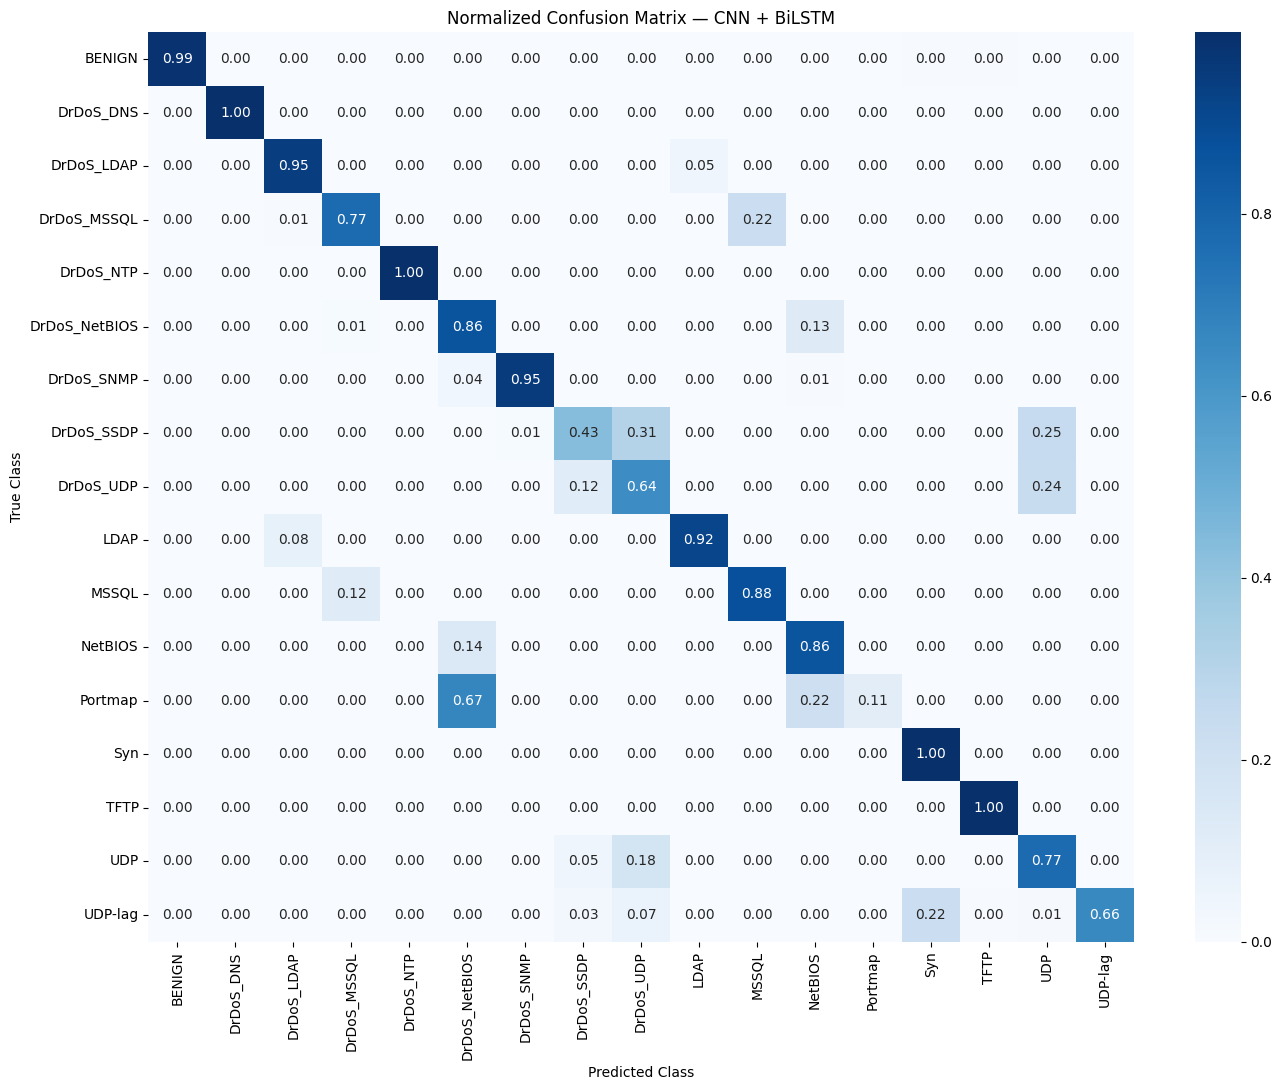

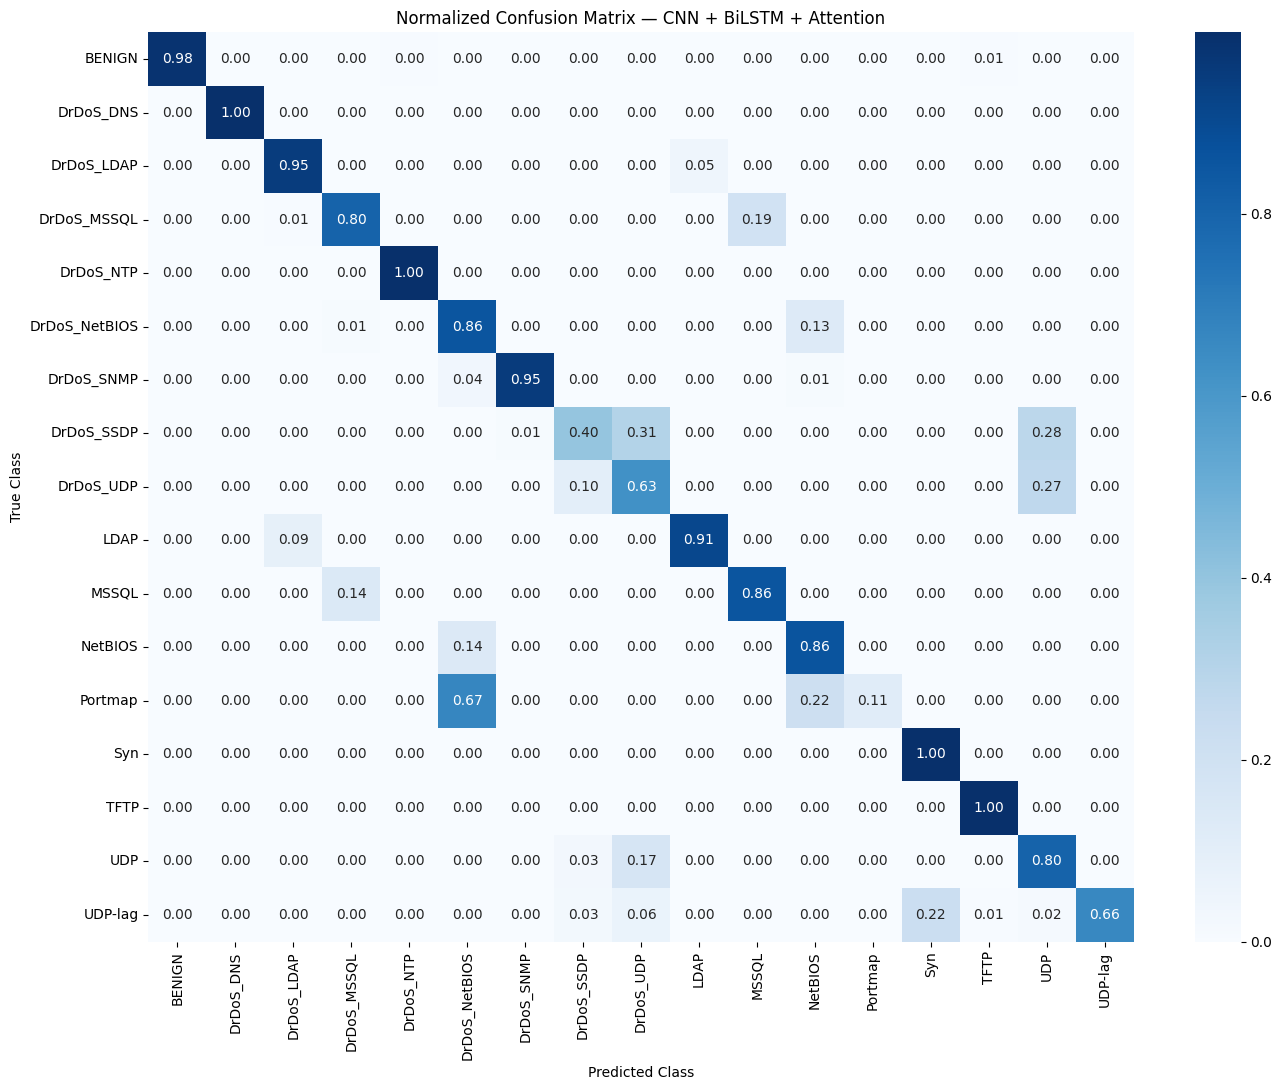

In [53]:
# ============================================================
# CONFUSION MATRICES — ALL FOUR MODELS
# ============================================================
# Shows how each model classifies the 17 DDoS attack classes.
# Normalization makes the matrix easier to compare across
# classes with different numbers of samples.
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

models_cm = {
    "CNN": cnn_cm,
    "BiLSTM": bilstm_cm,
    "CNN + BiLSTM": cnn_bilstm_cm,
    "CNN + BiLSTM + Attention": hybrid_cm
}

for model_name, cm in models_cm.items():

    # Normalize each row by the number of actual samples
    cm_normalized = cm.astype("float") / cm.sum(axis=1, keepdims=True)

    # Handle any class with zero samples safely
    cm_normalized = np.nan_to_num(cm_normalized)

    plt.figure(figsize=(14, 11))

    sns.heatmap(
        cm_normalized,
        annot=True,
        fmt=".2f",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.title(f"Normalized Confusion Matrix — {model_name}")
    plt.xlabel("Predicted Class")
    plt.ylabel("True Class")
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

In [54]:
# ============================================================
# PER-CLASS CLASSIFICATION REPORT COMPARISON
# ============================================================
# Compares F1-score for every DDoS attack class across
# all four models.
# ============================================================

class_f1_comparison = pd.DataFrame({
    "Class": class_names,

    "CNN F1": [
        cnn_report[class_name]["f1-score"]
        for class_name in class_names
    ],

    "BiLSTM F1": [
        bilstm_report[class_name]["f1-score"]
        for class_name in class_names
    ],

    "CNN + BiLSTM F1": [
        cnn_bilstm_report[class_name]["f1-score"]
        for class_name in class_names
    ],

    "CNN + BiLSTM + Attention F1": [
        hybrid_report[class_name]["f1-score"]
        for class_name in class_names
    ]
})

class_f1_comparison

,Class,CNN F1,BiLSTM F1,CNN + BiLSTM F1,CNN + BiLSTM + Attention F1
0,BENIGN,0.919517,0.967949,0.970999,0.965739
1,DrDoS_DNS,0.996445,0.998408,0.998285,0.998265
2,DrDoS_LDAP,0.914696,0.933339,0.932181,0.932504
3,DrDoS_MSSQL,0.773261,0.797215,0.796115,0.805375
4,DrDoS_NTP,0.998492,0.998911,0.999413,0.999162
5,DrDoS_NetBIOS,0.818635,0.833022,0.833766,0.832154
6,DrDoS_SNMP,0.972811,0.973677,0.973720,0.973564
7,DrDoS_SSDP,0.400045,0.475668,0.524049,0.508563
8,DrDoS_UDP,0.570842,0.601799,0.603900,0.599124
9,LDAP,0.903029,0.927454,0.928606,0.927596


In [55]:
# ============================================================
# COMPLETE CLASSIFICATION REPORT — HYBRID MODEL
# ============================================================

hybrid_classification_report = pd.DataFrame(hybrid_report).T

hybrid_classification_report

,precision,recall,f1-score,support
BENIGN,0.947479,0.984716,0.965739,458.000000
DrDoS_DNS,0.998856,0.997675,0.998265,24513.000000
DrDoS_LDAP,0.913320,0.952510,0.932504,10697.000000
DrDoS_MSSQL,0.808072,0.802697,0.805375,21951.000000
DrDoS_NTP,0.998827,0.999497,0.999162,5966.000000
DrDoS_NetBIOS,0.809870,0.855699,0.832154,19792.000000
DrDoS_SNMP,0.993242,0.954650,0.973564,25711.000000
DrDoS_SSDP,0.707067,0.397084,0.508563,12826.000000
DrDoS_UDP,0.572456,0.628398,0.599124,15452.000000
LDAP,0.944395,0.911384,0.927596,9355.000000


In [56]:
# ============================================================
# ABLATION ANALYSIS — MACRO F1
# ============================================================
# Measures the change in Macro F1 when:
# 1. BiLSTM is added to CNN
# 2. Attention is added to CNN + BiLSTM
# ============================================================

cnn_f1 = cnn_metrics["Macro F1"]
cnn_bilstm_f1 = cnn_bilstm_metrics["Macro F1"]
hybrid_f1 = hybrid_metrics["Macro F1"]

bilstm_contribution = cnn_bilstm_f1 - cnn_f1
attention_contribution = hybrid_f1 - cnn_bilstm_f1

ablation_results = pd.DataFrame({
    "Stage": [
        "CNN",
        "CNN + BiLSTM",
        "CNN + BiLSTM + Attention"
    ],

    "Macro F1": [
        cnn_f1,
        cnn_bilstm_f1,
        hybrid_f1
    ]
})

ablation_results["Macro F1 (%)"] = (
    ablation_results["Macro F1"] * 100
)

print("ABLATION ANALYSIS")
print("=" * 60)

print(
    f"BiLSTM contribution: "
    f"{bilstm_contribution * 100:+.2f} percentage points"
)

print(
    f"Attention contribution: "
    f"{attention_contribution * 100:+.2f} percentage points"
)

print("=" * 60)

ablation_results

ABLATION ANALYSIS
BiLSTM contribution: +2.58 percentage points
Attention contribution: -0.04 percentage points


,Stage,Macro F1,Macro F1 (%)
0,CNN,0.793866,79.386580
1,CNN + BiLSTM,0.819668,81.966758
2,CNN + BiLSTM + Attention,0.819282,81.928201


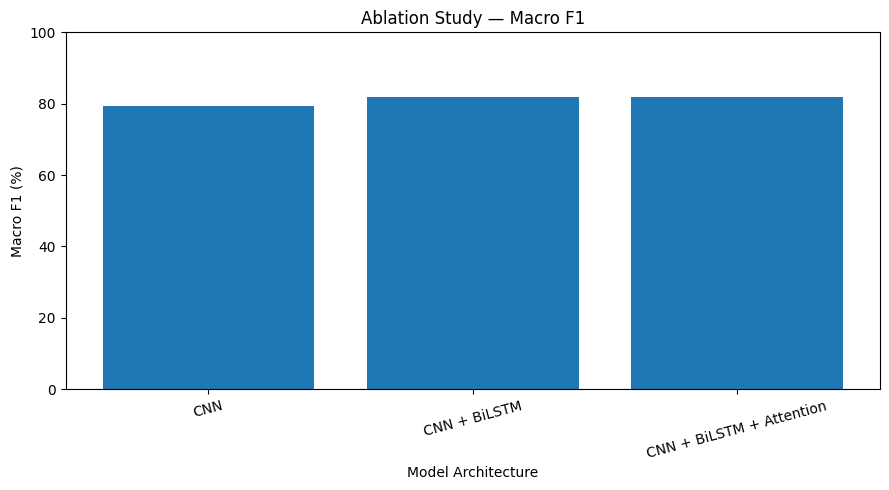

In [57]:
# ============================================================
# ABLATION PLOT
# ============================================================

plt.figure(figsize=(9, 5))

plt.bar(
    ablation_results["Stage"],
    ablation_results["Macro F1 (%)"]
)

plt.ylabel("Macro F1 (%)")
plt.xlabel("Model Architecture")
plt.title("Ablation Study — Macro F1")
plt.xticks(rotation=15)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()